In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "pyproject.toml").exists(), "Run from the repository root."
pd.set_option("display.max_columns", 30)

In [2]:
source_metadata = json.loads((PROJECT_ROOT / "data/source_metadata.json").read_text())
display(pd.Series(source_metadata, name="Recorded value").to_frame())

raw_path = PROJECT_ROOT / "data/raw/yellow_tripdata_2026-01.parquet"
digest = hashlib.sha256()
with raw_path.open("rb") as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
        digest.update(chunk)

actual_sha256 = digest.hexdigest()
expected_sha256 = source_metadata["raw_sha256"]
print("Checksum matches preserved metadata:", actual_sha256 == expected_sha256)
print("SHA-256:", actual_sha256)

,Recorded value
study_title,Robust Detection of Anomalous Taxi Fares Using...
source_page,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
source_url,https://d37ci6vzurychx.cloudfront.net/trip-dat...
retrieval_date,2026-11-01
raw_filename,yellow_tripdata_2026-01.parquet
raw_file_size_bytes,64165080
raw_sha256,8b3933fe6f0d7b6d8826613c0dd724edc680ff7c49e2bd...
raw_record_count,3724889
eligible_record_count,2278082
sample_size,10000


Checksum matches preserved metadata: True
SHA-256: 8b3933fe6f0d7b6d8826613c0dd724edc680ff7c49e2bd4c7635c05102728637


,stage,records_before,records_removed,records_after,retained_percent_of_original
0,original_records,3724889,0,3724889,100.00%
1,pickup_in_january_2026,3724889,7,3724882,100.00%
2,standard_rate_code_1,3724882,1334391,2390491,64.18%
3,positive_trip_distance,2390491,17940,2372551,63.69%
4,positive_fare_amount,2372551,33753,2338798,62.79%
5,duration_at_least_1_minute,2338798,47068,2291730,61.52%
6,passenger_count_at_least_1,2291730,13648,2278082,61.16%
7,eligible_records,2278082,0,2278082,61.16%
8,deterministic_sample,2278082,2268082,10000,0.27%


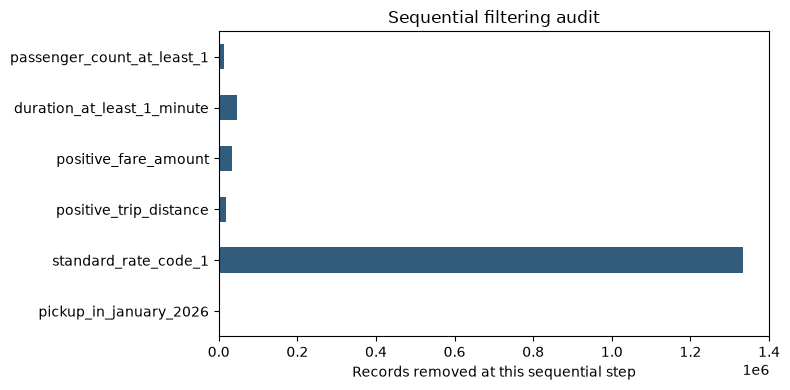

In [3]:
flow = pd.read_csv(PROJECT_ROOT / "outputs/tables/data_quality_flow.csv")
flow["retained_percent_of_original"] = 100 * flow["records_after"] / flow.loc[0, "records_after"]
display(flow.style.format({"retained_percent_of_original": "{:.2f}%"}))

plot_flow = flow.loc[~flow["stage"].isin(["original_records", "eligible_records", "deterministic_sample"])]
ax = plot_flow.plot.barh(x="stage", y="records_removed", legend=False, figsize=(8, 4), color="#315C7C")
ax.set_xlabel("Records removed at this sequential step")
ax.set_ylabel("")
ax.set_title("Sequential filtering audit")
plt.tight_layout()
plt.show()

In [4]:
ranges = pd.read_csv(PROJECT_ROOT / "outputs/tables/data_quality_ranges.csv")
missingness = pd.read_csv(PROJECT_ROOT / "outputs/tables/data_quality_missingness.csv")
print("Observed ranges after filtering and sampling")
display(ranges)
print("Missingness evidence")
display(missingness.loc[missingness["missing_count"].gt(0)])
print("No rows above means the reported final sample has no missing values in its exported fields.")

Observed ranges after filtering and sampling


,dataset,variable,minimum,maximum
0,raw_relevant,fare_amount,-2555.20,2555.200000
1,raw_relevant,trip_distance,0.00,269097.480000
2,raw_relevant,duration_min,-11.70,7507.900000
3,raw_relevant,passenger_count,0.00,9.000000
4,eligible_population,fare_amount,0.40,2555.200000
5,eligible_population,trip_distance,0.01,295.990000
6,eligible_population,duration_min,1.00,5293.333333
7,eligible_population,passenger_count,1.00,6.000000
8,final_sample,fare_amount,3.00,152.100000
9,final_sample,trip_distance,0.03,33.510000


Missingness evidence


,dataset,column,missing_count,missing_percent
3,raw_relevant,passenger_count,1088058,29.210481
5,raw_relevant,RatecodeID,1088058,29.210481


No rows above means the reported final sample has no missing values in its exported fields.


In [5]:
model_data = pd.read_csv(
    PROJECT_ROOT / "data/processed/taxi_modeling_50000.csv",
    parse_dates=["pickup_datetime", "dropoff_datetime"],
)

columns_to_show = [
    "source_row_id", "pickup_datetime", "dropoff_datetime", "fare_amount",
    "trip_distance", "duration_min", "passenger_count", "pickup_hour",
    "pickup_hour_sin", "pickup_hour_cos", "is_weekend", "split",
]
display(model_data[columns_to_show].head())

,source_row_id,pickup_datetime,dropoff_datetime,fare_amount,trip_distance,duration_min,passenger_count,pickup_hour,pickup_hour_sin,pickup_hour_cos,is_weekend,split
0,2487225,2026-01-30 14:29:58,2026-01-30 14:45:03,14.9,1.60,15.083333,1.0,14,-0.500000,-0.866025,0,train
1,2284541,2026-01-28 11:06:45,2026-01-28 11:10:57,5.8,0.63,4.200000,1.0,11,0.258819,-0.965926,0,train
2,688737,2026-01-09 16:44:19,2026-01-09 17:08:20,24.7,4.36,24.016667,1.0,16,-0.866025,-0.500000,0,train
3,1180176,2026-01-14 20:16:52,2026-01-14 20:27:17,11.4,1.66,10.416667,1.0,20,-0.866025,0.500000,0,train
4,1880517,2026-01-22 16:24:58,2026-01-22 16:43:05,16.3,2.18,18.116667,1.0,16,-0.866025,-0.500000,0,test


In [6]:
metadata = json.loads((PROJECT_ROOT / "data/modeling_metadata.json").read_text())
display(pd.Series(metadata, name="Value").to_frame())

,Value
eligible_population_size,2278082
modeling_sample_size,50000
training_size,40000
test_size,10000
test_fraction,0.2
selection_seed,42
split_seed,42
selection_method,prefix of NumPy Generator permutation
split_method,sklearn train_test_split with shuffle=True
benchmark_identity_verified,True


In [7]:
split_summary = pd.read_csv(PROJECT_ROOT / "outputs/tables/model_split_summary.csv")
display(split_summary)

train_ids = set(model_data.loc[model_data["split"].eq("train"), "source_row_id"])
test_ids = set(model_data.loc[model_data["split"].eq("test"), "source_row_id"])

assert len(model_data) == 50_000
assert len(train_ids) == 40_000
assert len(test_ids) == 10_000
assert train_ids.isdisjoint(test_ids)
assert len(train_ids | test_ids) == 50_000
print("All split checks passed; train and test identities are disjoint and exhaustive.")

,split,record_count,fraction,unique_source_ids,source_id_sha256
0,all,50000,1.0,50000,bbb8982488eb73d9bc8637ae27735972c71f35be2e7d65...
1,train,40000,0.8,40000,199b0d9697584054d47e44638848bc40fb1b2467dbf079...
2,test,10000,0.2,10000,cb0b169f72b002de2ad4ff2a5a0cc87ab1e80931dd6d5d...


All split checks passed; train and test identities are disjoint and exhaustive.
